# 02 - Handling Missing Values
**Goal:** compare fill strategies and choose the best one.

In [1]:
import sys; sys.path.append("..")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from src import cleaning as cl
RAW = "../data/raw/airline_passengers_dirty.csv"
plt.rcParams["figure.figsize"] = (10, 4)

## Load with a regular monthly index
`load_series` removes duplicates and inserts NaN for missing months.

In [2]:
s = cl.load_series(RAW)
print(cl.missing_report(s))

{'missing': 10, 'percent': 6.94}


## Apply four fill methods

In [3]:
methods = ['ffill', 'bfill', 'linear', 'time']
filled = {m: cl.fill_missing(s, m) for m in methods}
pd.DataFrame(filled)[s.isna()]

,ffill,bfill,linear,time
Month,,,,
1950-01-01,118.0,126.0,122.0,122.000000
1953-06-01,229.0,264.0,246.5,246.786885
1954-02-01,204.0,235.0,219.5,220.288136
1954-12-01,203.0,242.0,222.5,222.180328
1956-07-01,374.0,405.0,389.5,389.245902
1957-05-01,348.0,422.0,385.0,384.393443
1957-11-01,347.0,336.0,341.5,341.409836
1959-02-01,360.0,406.0,383.0,384.169492
1960-09-01,606.0,461.0,533.5,532.311475


## Visual comparison (zoomed around a gap)

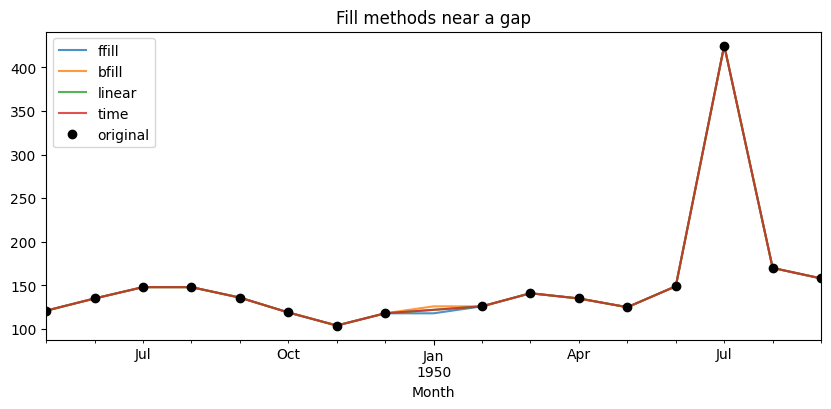

In [4]:
gap = s.index[s.isna()][0]
win = slice(gap - pd.DateOffset(months=8), gap + pd.DateOffset(months=8))
for m in methods:
    filled[m][win].plot(label=m, alpha=.8)
s[win].plot(color='k', marker='o', label='original', ls='')
plt.legend(); plt.title('Fill methods near a gap'); plt.show()

**Choice:** time-based interpolation follows the trend and seasonality best, whereas ffill/bfill create flat steps. We use `time`.

In [5]:
s_filled = cl.fill_missing(s, 'time')
print('Remaining NaN:', s_filled.isna().sum())

Remaining NaN: 0
